In [1]:
from sklearn.datasets import load_iris
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame

print(type(iris), type(df))

<class 'sklearn.utils._bunch.Bunch'> <class 'pandas.DataFrame'>


In [3]:
df.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


In [4]:
print(iris.target_names)

['setosa' 'versicolor' 'virginica']


In [5]:
df.shape

(150, 5)

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X = df[iris.feature_names]
y = df["target"]

In [8]:
print(X.shape, y.shape)

(150, 4) (150,)


In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(len(X_train), len(X_test))

120 30


In [10]:
from sklearn.tree import DecisionTreeClassifier

model = DecisionTreeClassifier(max_depth=3, random_state=42)
model.fit(X_train, y_train)

print("Model trained!")

Model trained!


In [11]:
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

y_pred = model.predict(X_test)

acc = accuracy_score(y_test, y_pred)
cm = confusion_matrix(y_test, y_pred)
print(f"Accuracy: {acc:.4f}")
#print("Confusion matrix:\n", cm)


Accuracy: 0.9667


<Figure size 300x300 with 0 Axes>

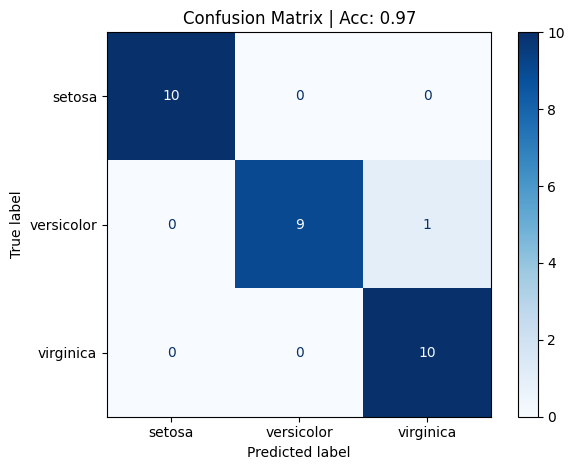

In [12]:
plt.figure(figsize=(3, 3))
disp = ConfusionMatrixDisplay(cm, display_labels=iris.target_names).plot(cmap=plt.cm.Blues)
plt.title(f"Confusion Matrix | Acc: {acc:.2f}")
plt.tight_layout()

In [13]:
new_flower = pd.DataFrame(
    [[5.1, 3.5, 1.4, 0.2]],
    columns=iris.feature_names
)

predicted_id = model.predict(new_flower)[0]
print("Predicted species:", iris.target_names[predicted_id])


Predicted species: setosa


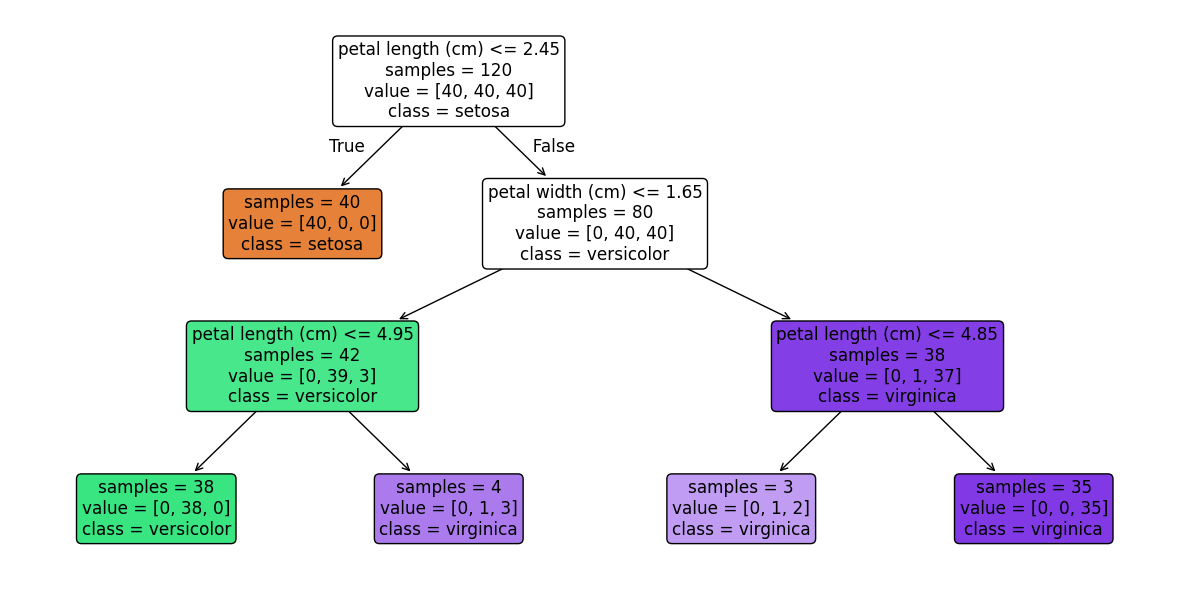

In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 6))
plot_tree(model, feature_names=iris.feature_names,
          class_names=list(iris.target_names), impurity=False,
          filled=True, rounded=True)
plt.tight_layout()
plt.show()
